In [73]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import ast

In [74]:
# Read in woke
wokeGames = pd.read_csv("Data/wokeGames.csv")
wokeGames.drop(columns=["Unnamed: 0"], inplace=True)

notWokeGames = pd.read_csv("Data/notWokeGames.csv")
notWokeGames.drop(columns=["Unnamed: 0"], inplace=True)


In [75]:
# Read in file
steam = pd.read_csv("Data/games_march2025_cleaned.csv")
steam = steam.drop(columns=["about_the_game", "release_date", "short_description",
                            "detailed_description", "support_url", "support_email",
                            "website", "reviews", "metacritic_score", "metacritic_url",
                            "notes", "score_rank", "header_image", "packages", "developers", "publishers",
                            "screenshots", "movies", "estimated_owners", "name"]) #NEED TO WRITE SOMETHING FOR TAGS
steam["isWoke"] = steam["appid"].isin(wokeGames["0"])
steam["isNotWoke"] = steam["appid"].isin(notWokeGames["0"])

#steam_temp = steam.drop(columns=["supported_languages", "full_audio_languages", "categories", "genres"])
#correlation_matrix = steam_temp.corr()
#plt.figure(figsize=(20,20))
#sns.heatmap(correlation_matrix, fmt="g")
#plt.show()


In [76]:
def dummyVariable(name_of_feature):
    global steam
    steam["temp"] = steam[name_of_feature].apply(ast.literal_eval)
    exploded_languages = steam["temp"].explode()
    # turn many values of the same langauge from the explosion into "max", whether it supports that language or not
    dummies_languages = pd.get_dummies(exploded_languages).groupby(level=0).max()
    dummies_languages.columns += "_" + name_of_feature
    #print(dummies_languages.head())
    steam = pd.concat([steam, dummies_languages], axis=1)
    steam.drop(columns=["temp", name_of_feature], inplace=True)

dummyVariable("supported_languages")
dummyVariable("full_audio_languages")
dummyVariable("categories")
dummyVariable("genres")
dummyVariable("tags")


In [77]:

print(steam["isWoke"].sum())
print(steam["isNotWoke"].sum())
steam_curated_woke = steam.loc[steam["isWoke"] == True]
steam_curated_notwoke = steam.loc[steam["isNotWoke"] == True]
steam_curated = pd.concat([steam_curated_woke, steam_curated_notwoke], axis=0)
print(steam_curated.info())
print(steam_curated.head())

907
519
<class 'pandas.DataFrame'>
Index: 1426 entries, 0 to 80684
Columns: 762 entries, appid to e-sports_tags
dtypes: bool(743), float64(1), int64(18)
memory usage: 1.2 MB
None
    appid  required_age  price  dlc_count  windows    mac  linux  \
0     730             0   0.00          1     True  False   True   
4  359550            17   3.99          9     True  False  False   
5     440             0   0.00          1     True  False   True   
6  105600             0   9.99          2     True   True   True   
8    4000             0   5.99          0     True   True   True   

   achievements  recommendations  user_score  ...  Well-Written_tags  \
0             1          4401572           0  ...              False   
4             0          1165929           0  ...              False   
5           520            41587           0  ...              False   
6           115          1098792           0  ...              False   
8            29           984713           0  ...   

                      appid  required_age     price  dlc_count  windows  \
appid              1.000000     -0.095872  0.163273  -0.040433      NaN   
required_age      -0.095872      1.000000  0.265845   0.080507      NaN   
price              0.163273      0.265845  1.000000   0.147831      NaN   
dlc_count         -0.040433      0.080507  0.147831   1.000000      NaN   
windows                 NaN           NaN       NaN        NaN      NaN   
...                     ...           ...       ...        ...      ...   
World War I_tags  -0.027302      0.007631 -0.008740  -0.001213      NaN   
World War II_tags -0.030727      0.014393  0.053026   0.004686      NaN   
Wrestling_tags     0.027765      0.017677  0.059761   0.035806      NaN   
Zombies_tags      -0.045724      0.188246  0.082943   0.013624      NaN   
e-sports_tags     -0.051781     -0.035635  0.048634   0.067424      NaN   

                        mac     linux  achievements  recommendations  \
appid             -0.198500

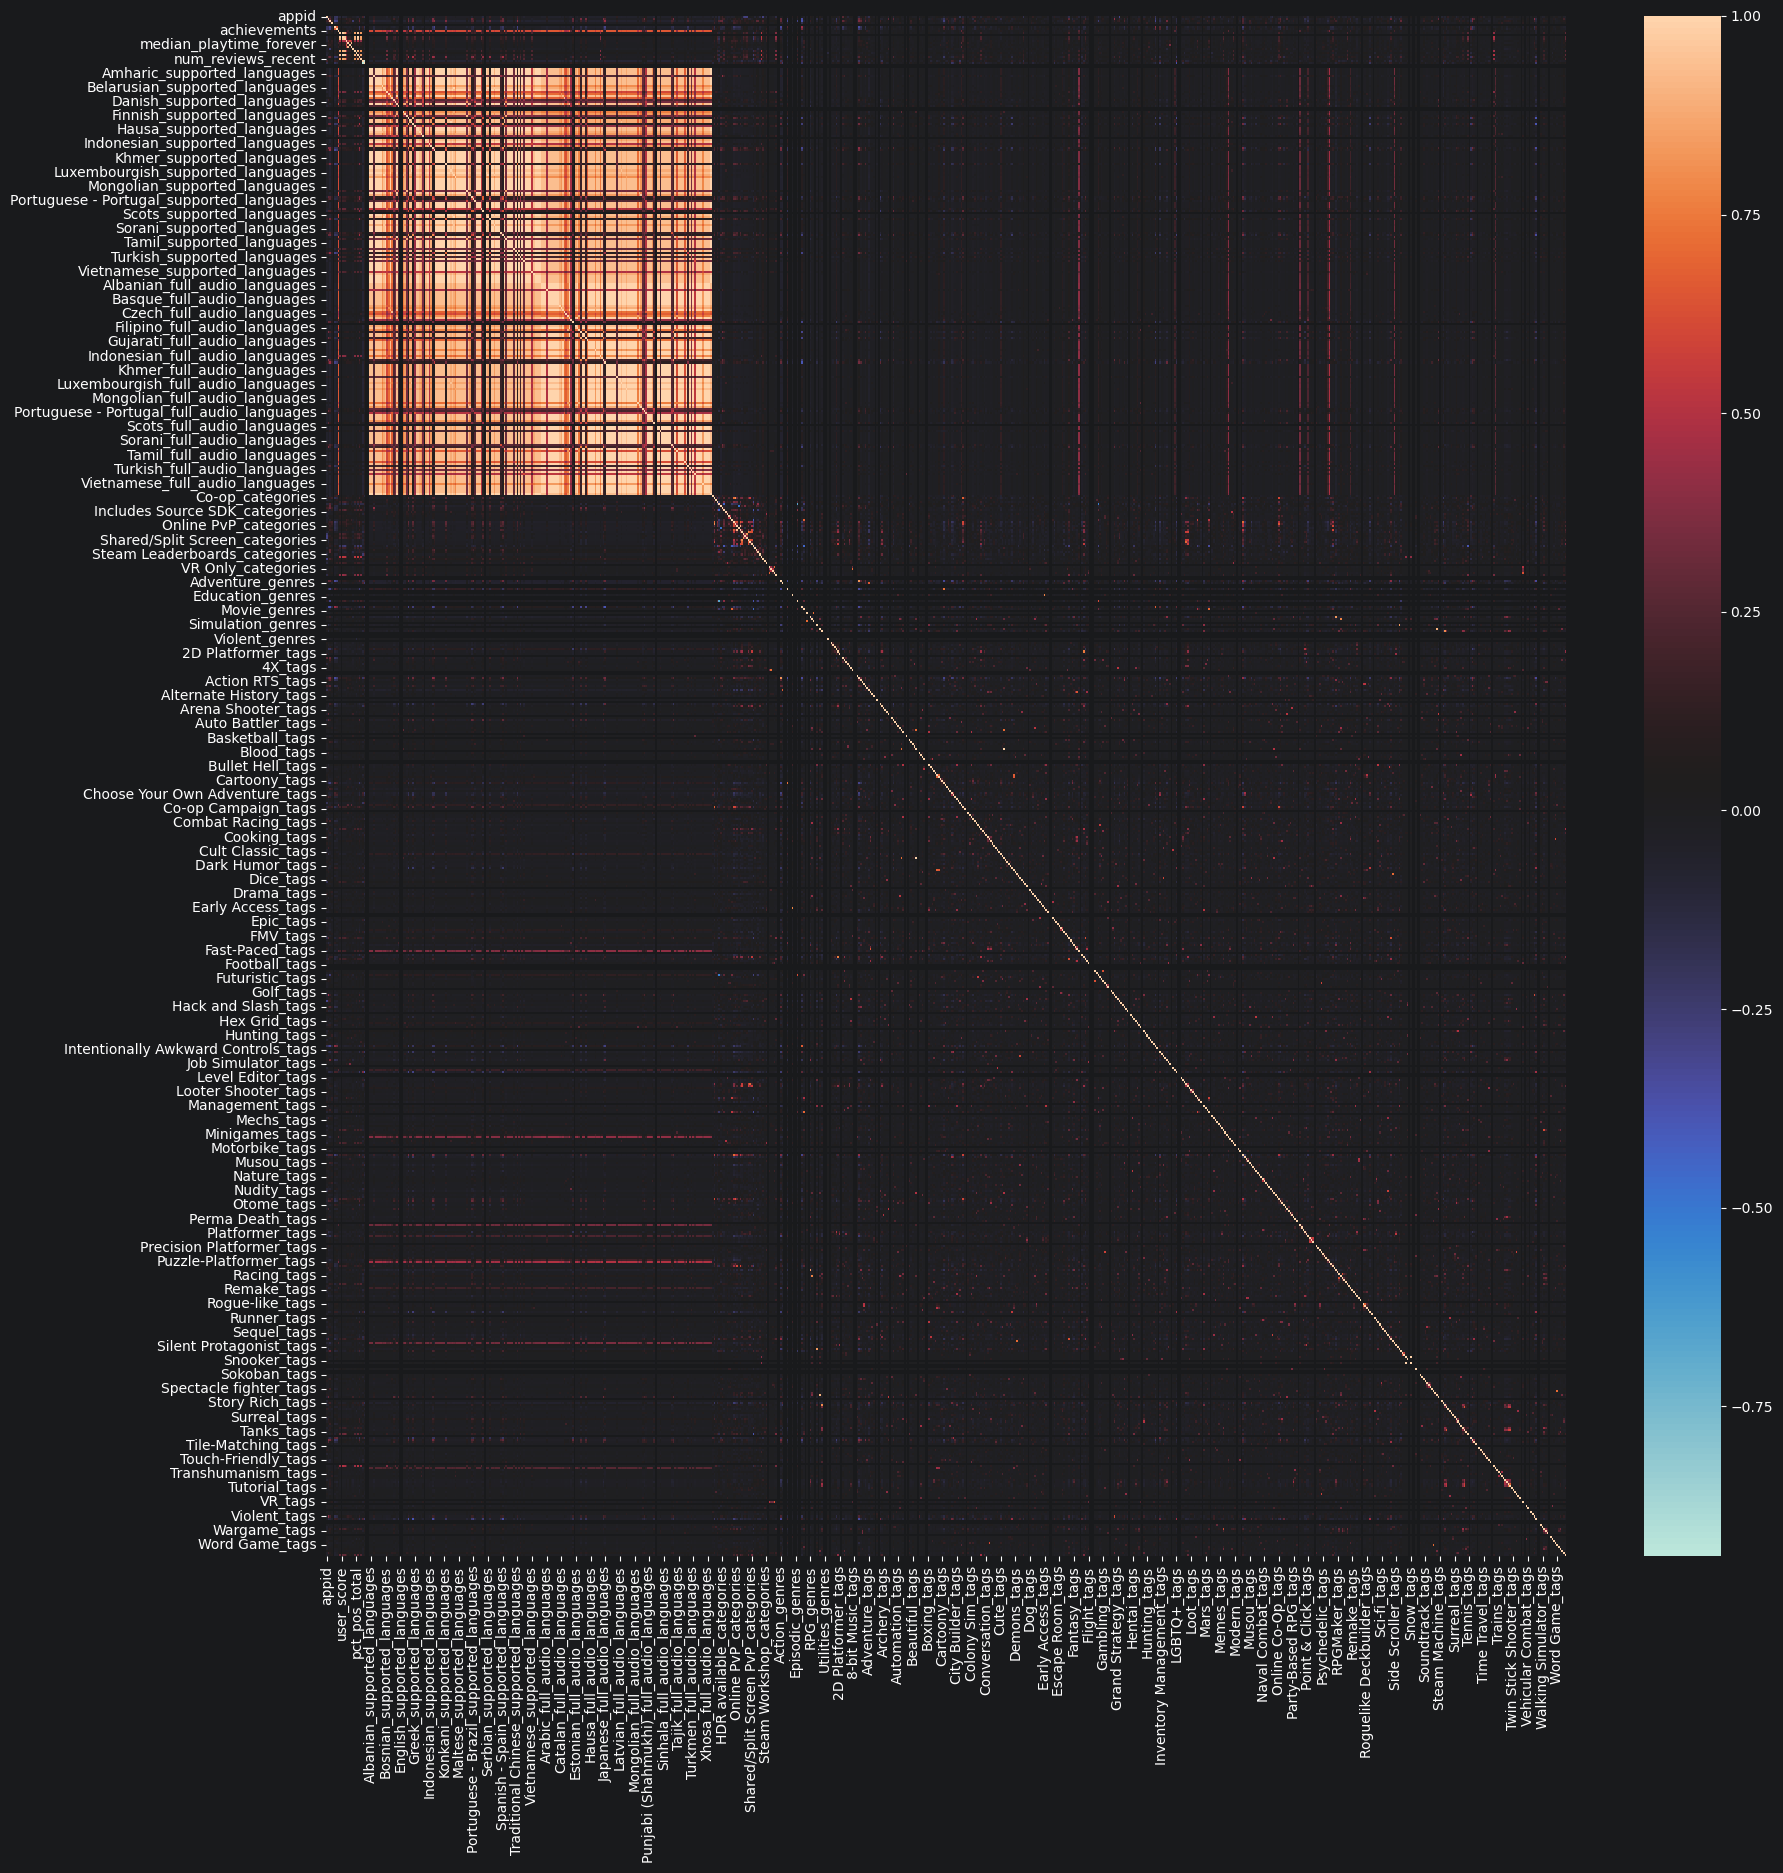

In [78]:
correlation_matrix = steam_curated.corr()
correlation_matrix.to_csv("correlation.csv")
print(correlation_matrix)
plt.figure(figsize=(20,20))
sns.heatmap(correlation_matrix, fmt="g", cmap="icefire")
plt.show()